# 🌾 AgriSense: Understanding Agricultural Markets Through Data

### Exploratory Data Analysis (EDA) & Statistics

**Project:** AI-Powered Crop Price Estimation and Online Bidding Platform

**Region:** Jammu & Kashmir, India

**Objective:** To explore agricultural listing data, discover market trends, identify data-quality issues and prepare a reliable dataset for machine learning.

---

### The story behind this project

Imagine a farmer from Shopian who has harvested 100 quintals of apples.

He wants to sell his produce through an online bidding platform where buyers from different parts of India can participate.

But several questions arise:

- What starting price should the farmer set?
- Do different crops have different price patterns?
- Does crop quality affect the starting bid?
- Do prices vary between districts?
- Does the season influence agricultural prices?

We cannot answer these questions by guessing.

**We need data.**

In this notebook, we will investigate agricultural listing data using Python, Pandas, NumPy, Matplotlib and Seaborn.

Our goal is to turn raw agricultural records into meaningful insights that can support the AgriSense machine learning model.

**EDA & STATS PROJECT**


## 1. Setting Up Our Investigation

Before investigating the agricultural market, we need tools to work with the data.

We will use:

- **Pandas:** To load, manipulate and clean the dataset.
- **NumPy:** To perform numerical operations.
- **Matplotlib:** To create visualizations.
- **Seaborn:** To create statistical charts.

These libraries will help us understand the dataset without manually examining thousands of records.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Meet Our Dataset

Every investigation begins with evidence.

Our evidence is an agricultural bidding dataset containing information about crop listings in Jammu & Kashmir.

Each row represents an agricultural listing, while each column describes an attribute of that listing.

For example, a record may contain:

- District where the crop is listed.
- Name and variety of the crop.
- Crop grade and season.
- Available quantity in quintals.
- Starting bid price per quintal.
- Other agricultural and market-related information.

Our main variable of interest is:

**`starting_bid_price_inr_per_quintal`**

This is the value we ultimately want to understand and predict using machine learning.

Let's load the dataset and inspect our first few records.

In [2]:
df = pd.read_csv("jk_farm_bidding_eda_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Understanding the Structure of Our Data

Before cleaning anything, we need to understand what we are working with.

We will investigate three basic questions:

1. How many records and columns are available?
2. What information does each column contain?
3. What are the data types of these columns?

We will also examine the first and last records to understand how the dataset is organized.

This step is important because we cannot clean or analyze data properly without understanding its structure.

In [3]:
df.head()

,lot_id,listing_date,district,crop,variety,grade,season,quantity_quintals,quality_score,storage_type,distance_to_major_mandi_km,transport_cost_per_quintal_inr,rainfall_mm_30d,avg_temperature_c,market_arrival_quintals,historical_modal_price_inr_per_quintal,starting_bid_price_inr_per_quintal
0,JKLOT006370,2025-12-19,Pulwama,Plum,Local,B,Winter,25.3,71.7,Cold Storage,22.2,1.55,25.3,6.9,58.2,5113.48,4712.10
1,JKLOT017179,2023-02-11,Udhampur,Maize,Yellow,B,Winter,14.1,70.7,NaN,82.5,9.60,23.5,7.3,32.9,2861.61,2746.23
2,JKLOT012536,2024-01-28,Rajouri,Potato,Local,A,Winter,53.8,76.1,NaN,81.2,8.40,13.2,15.4,311.7,1559.27,1248.77
3,JKLOT018416,2024-10-15,Budgam,Pear,Patharnakh,A,Autumn,334.8,57.4,Cold Storage,135.9,11.65,9.2,18.6,115.9,6076.14,5346.12
4,JKLOT012664,2024-04-06,Kupwara,Plum,Santa Rosa,Mixed,Spring,18.7,76.9,NaN,47.5,5.40,8.5,21.6,185.4,6396.93,5434.49


In [4]:
df.tail()

,lot_id,listing_date,district,crop,variety,grade,season,quantity_quintals,quality_score,storage_type,distance_to_major_mandi_km,transport_cost_per_quintal_inr,rainfall_mm_30d,avg_temperature_c,market_arrival_quintals,historical_modal_price_inr_per_quintal,starting_bid_price_inr_per_quintal
25175,JKLOT001769,2023-04-24,Kulgam,Apple,Royal Delicious,C,Spring,103.3,54.5,Controlled Atmosphere,339.4,17.52,25.3,9.5,218.2,8915.72,8004.38
25176,JKLOT009930,2023-04-20,Baramulla,Pear,Patharnakh,Mixed,Spring,161.1,79.7,Cold Storage,523.8,30.45,12.8,17.9,198.4,5302.02,4342.64
25177,JKLOT003241,2024-10-23,Pulwama,Tomato,Local,C,Autumn,111.1,74.5,NaN,324.1,25.02,7.8,23.9,44.0,1486.21,1380.53
25178,JKLOT013498,2022-02-21,Kupwara,Cherry,Double,B,Winter,243.5,72.0,Cold Storage,103.0,6.56,15.4,12.4,569.2,7774.44,6162.52
25179,JKLOT023588,2024-07-31,Udhampur,Apricot,Local,A+,Summer,12.6,92.7,Cold Storage,365.2,25.59,14.2,11.8,231.8,14362.73,12402.58


In [5]:
df.shape

(25180, 17)

In [6]:
for i in df.columns:
    print(i)

lot_id
listing_date
district
crop
variety
grade
season
quantity_quintals
quality_score
storage_type
distance_to_major_mandi_km
transport_cost_per_quintal_inr
rainfall_mm_30d
avg_temperature_c
market_arrival_quintals
historical_modal_price_inr_per_quintal
starting_bid_price_inr_per_quintal


### Understanding Column Data Types

Not all information in our dataset is the same.

For example:

- Quantity and starting bid price are numerical variables.
- Crop, district and season are categorical variables.
- Listing date is a date-related variable.

Understanding data types helps us choose appropriate cleaning techniques and statistical methods.

Let's inspect the data types of all columns.

In [8]:
print("Datatypes of columns")

for i in df.columns:
    print(i, " -> ", df[i].dtypes)

Datatypes of columns
lot_id  ->  object
listing_date  ->  object
district  ->  object
crop  ->  object
variety  ->  object
grade  ->  object
season  ->  object
quantity_quintals  ->  float64
quality_score  ->  float64
storage_type  ->  object
distance_to_major_mandi_km  ->  float64
transport_cost_per_quintal_inr  ->  float64
rainfall_mm_30d  ->  float64
avg_temperature_c  ->  float64
market_arrival_quintals  ->  float64
historical_modal_price_inr_per_quintal  ->  float64
starting_bid_price_inr_per_quintal  ->  float64


### Getting Our First Statistical Overview

Now that we understand the structure, let's examine the numerical characteristics of the dataset.

The `describe()` function provides:

- **Count:** Number of available observations.
- **Mean:** Average value.
- **Standard deviation:** How much values vary.
- **Minimum:** Smallest value.
- **25%, 50%, 75%:** Quartiles and median.
- **Maximum:** Largest value.

This gives us our first statistical picture of agricultural quantities, prices and other numerical features.

We will later investigate these variables in greater detail.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25180 entries, 0 to 25179
Data columns (total 17 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   lot_id                                  25180 non-null  object 
 1   listing_date                            25180 non-null  object 
 2   district                                25180 non-null  object 
 3   crop                                    25180 non-null  object 
 4   variety                                 24729 non-null  object 
 5   grade                                   25180 non-null  object 
 6   season                                  25180 non-null  object 
 7   quantity_quintals                       25180 non-null  float64
 8   quality_score                           24877 non-null  float64
 9   storage_type                            16233 non-null  object 
 10  distance_to_major_mandi_km              25180 non-null  fl

In [10]:
df.describe()

,quantity_quintals,quality_score,distance_to_major_mandi_km,transport_cost_per_quintal_inr,rainfall_mm_30d,avg_temperature_c,market_arrival_quintals,historical_modal_price_inr_per_quintal,starting_bid_price_inr_per_quintal
count,25180.000000,24877.00000,25180.000000,25180.000000,24978.000000,25180.000000,25180.000000,25030.000000,25180.000000
mean,78.750659,74.92727,130.618542,9.666702,17.996709,16.998054,244.436183,16354.025785,14425.097469
std,94.205605,11.92007,96.206189,5.399472,14.698410,7.966017,317.718145,32734.051537,29031.068339
min,10.000000,-12.00000,-15.000000,1.000000,0.000000,-8.000000,5.000000,699.580000,621.720000
25%,30.700000,66.90000,62.600000,5.830000,7.300000,11.600000,75.800000,4501.112500,3930.990000
50%,54.400000,75.10000,109.800000,8.700000,14.100000,17.000000,148.700000,7764.660000,6825.420000
75%,96.800000,83.10000,174.900000,12.520000,24.800000,22.400000,294.300000,14024.922500,12362.847500
max,5747.400000,145.00000,1800.000000,45.190000,147.400000,42.000000,12000.000000,353147.510000,335722.040000


## 4. Cleaning Our Agricultural Data

Before trusting our analysis, we must check whether our dataset contains incomplete or inconsistent information.

Imagine a farmer's listing contains the crop name and quantity but has no transport distance or market information.

Such incomplete records may affect our analysis and machine learning predictions.

Our first investigation is therefore to identify missing values.

We will calculate:

1. The number of missing values in each column.
2. The percentage of missing values in each column.

This will help us decide how to handle incomplete information rather than deleting records without investigation.

In [11]:
df.isnull().sum()

lot_id                                       0
listing_date                                 0
district                                     0
crop                                         0
variety                                    451
grade                                        0
season                                       0
quantity_quintals                            0
quality_score                              303
storage_type                              8947
distance_to_major_mandi_km                   0
transport_cost_per_quintal_inr               0
rainfall_mm_30d                            202
avg_temperature_c                            0
market_arrival_quintals                      0
historical_modal_price_inr_per_quintal     150
starting_bid_price_inr_per_quintal           0
dtype: int64

In [12]:
(df.isnull().sum() / len(df)) * 100

lot_id                                     0.000000
listing_date                               0.000000
district                                   0.000000
crop                                       0.000000
variety                                    1.791104
grade                                      0.000000
season                                     0.000000
quantity_quintals                          0.000000
quality_score                              1.203336
storage_type                              35.532168
distance_to_major_mandi_km                 0.000000
transport_cost_per_quintal_inr             0.000000
rainfall_mm_30d                            0.802224
avg_temperature_c                          0.000000
market_arrival_quintals                    0.000000
historical_modal_price_inr_per_quintal     0.595711
starting_bid_price_inr_per_quintal         0.000000
dtype: float64

### Deciding What to Do With Missing Values

Our missing-value analysis shows that the column `distance_to_major_mandi_km` contains approximately 35% missing values.

For this particular analysis, we have decided to remove this column because of its high proportion of missing observations and its lower priority in our current feature set.

For the remaining columns, we will use two common statistical techniques:

**1. Median Imputation**

We will fill missing numerical values with their median.

The median is less affected by extreme values than the mean, making it useful for numerical agricultural variables that may contain outliers.

**2. Mode Imputation**

We will fill missing categorical values with the most frequently occurring category.

This preserves a valid category rather than introducing an arbitrary value.

Our goal is to retain as much useful information as possible while improving data completeness.

In [19]:
# we will drop column "distance_to_major_mandi_km" as it is having 35% missing values and not so important column
df.drop(columns='distance_to_major_mandi_km', inplace=True)

In [20]:
numerical_cols = df.select_dtypes(
    include=np.number
).columns

categorical_cols = df.select_dtypes(
    include="object"
).columns

In [21]:
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

In [22]:
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

### Are We Counting the Same Listing More Than Once?

Another problem that can affect our analysis is duplicate data.

Imagine the same agricultural listing appears twice. If we count both records, our analysis may incorrectly suggest that more crops were listed or that certain market patterns occurred more frequently.

We will identify duplicate records and remove them.

This ensures that identical rows are not unnecessarily repeated in our cleaned dataset.

In [23]:
df.duplicated().sum()

180

In [24]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [25]:
df.duplicated().sum()

0

### Making Our Data Consistent

Data can be technically correct but still contain inconsistent formatting.

For example, the following entries may represent the same crop:

- apple
- Apple
- APPLE
- Apple followed by an extra space

A computer may treat these as different categories.

This can create incorrect counts and unnecessary categories in our analysis.

We will standardize:

- Crop names using title case.
- District names using title case.
- Grade labels using uppercase.

We will also remove unnecessary spaces.

This makes our categorical information more consistent and reliable.

In [27]:
df['crop'].value_counts()

crop
Apple      7043
Walnut     2449
Cherry     1958
Pear       1785
Maize      1402
Rice       1401
Plum       1357
Almond     1175
Peach      1156
Apricot    1112
Tomato     1090
Potato     1009
Saffron     869
Onion       617
Honey       504
 apple       38
WALNUT       23
maize        12
Name: count, dtype: int64

In [28]:
df["crop"] = df["crop"].str.strip().str.title()

df["district"] = df["district"].str.strip().str.title()

df["grade"] = df["grade"].str.strip().str.upper()

C:\Users\V\AppData\Local\Temp\ipykernel_20232\2537483084.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["crop"] = df["crop"].str.strip().str.title()
C:\Users\V\AppData\Local\Temp\ipykernel_20232\2537483084.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["district"] = df["district"].str.strip().str.title()
C:\Users\V\AppData\Local\Temp\ipykernel_20232\2537483084.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_inde

In [29]:
df["crop"].unique()

array(['Plum', 'Maize', 'Potato', 'Pear', 'Peach', 'Apple', 'Walnut',
       'Cherry', 'Onion', 'Apricot', 'Rice', 'Tomato', 'Saffron', 'Honey',
       'Almond'], dtype=object)

In [31]:
df["district"].unique()

array(['Pulwama', 'Udhampur', 'Rajouri', 'Budgam', 'Kupwara', 'Kulgam',
       'Shopian', 'Ganderbal', 'Kathua', 'Doda', 'Srinagar', 'Baramulla',
       'Jammu', 'Anantnag', 'Bandipora'], dtype=object)

### Extracting Time Information From Listing Dates

Agricultural prices may change throughout the year.

For example, the starting price of a crop during its harvest season may differ from its price during another period.

Our dataset contains a `listing_date` column.

Instead of working only with the complete date, we will extract two useful features:

- **Year:** Helps identify longer-term changes.
- **Month:** Helps investigate monthly and seasonal patterns.

This transformation will help us explore how time relates to agricultural listing prices.

In [30]:
df["listing_date"] = pd.to_datetime(
    df["listing_date"]
)

C:\Users\V\AppData\Local\Temp\ipykernel_20232\289512183.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["listing_date"] = pd.to_datetime(


In [32]:
df["year"] = df["listing_date"].dt.year

df["month"] = df["listing_date"].dt.month

C:\Users\V\AppData\Local\Temp\ipykernel_20232\744092626.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["year"] = df["listing_date"].dt.year
C:\Users\V\AppData\Local\Temp\ipykernel_20232\744092626.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["month"] = df["listing_date"].dt.month


Univaraite Analysis

### Our Data Is Now Cleaner

We have completed the initial data-cleaning stage.

So far, we have:

- Identified and handled missing values.
- Removed the selected high-missing-value column.
- Removed duplicate records.
- Standardized categorical values.
- Converted listing dates into datetime format.
- Extracted year and month information.

Now we can move from preparing our evidence to investigating what the agricultural market is actually telling us.

**The next stage is Exploratory Data Analysis.**

In [33]:
df["crop"].value_counts()

crop
Apple      7081
Walnut     2472
Cherry     1958
Pear       1785
Maize      1414
Rice       1401
Plum       1357
Almond     1175
Peach      1156
Apricot    1112
Tomato     1090
Potato     1009
Saffron     869
Onion       617
Honey       504
Name: count, dtype: int64

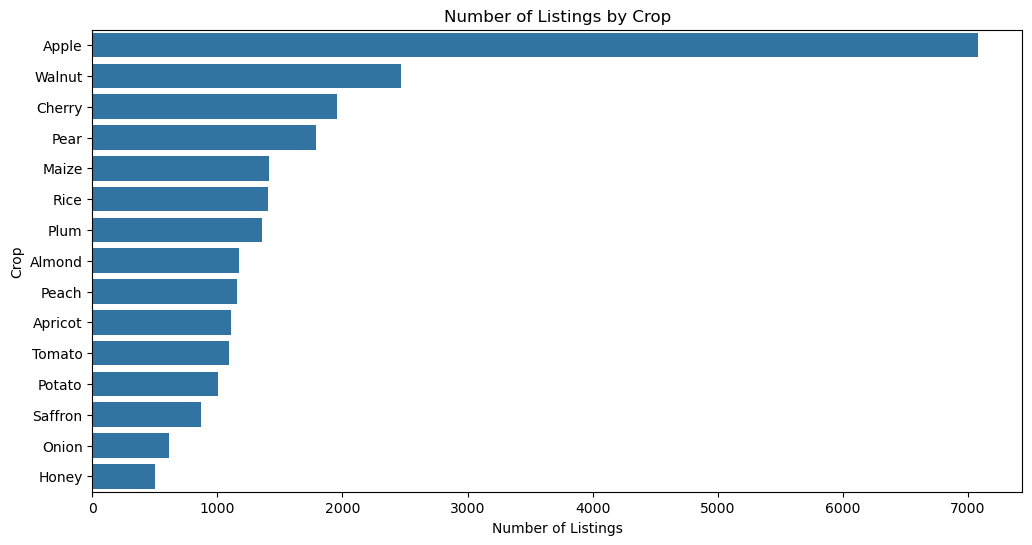

In [34]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="crop",
    order=df["crop"].value_counts().index
)

plt.title("Number of Listings by Crop")
plt.xlabel("Number of Listings")
plt.ylabel("Crop")

plt.show()

### 5.2 Understanding the Distribution of Starting Bid Prices

Our main objective is to predict the starting bid price.

But before building a prediction model, we must understand how prices are distributed.

Consider two possibilities:

- Most crops have prices concentrated around a similar range.
- A small number of crops have exceptionally high or low prices.

These patterns are important because agricultural prices may vary considerably depending on crop type, quality and market conditions.

We will use a histogram with a KDE curve.

**Why a histogram?**

A histogram is suitable for numerical data because it groups values into intervals, allowing us to see where observations are concentrated.

The KDE curve provides a smoothed view of the distribution.

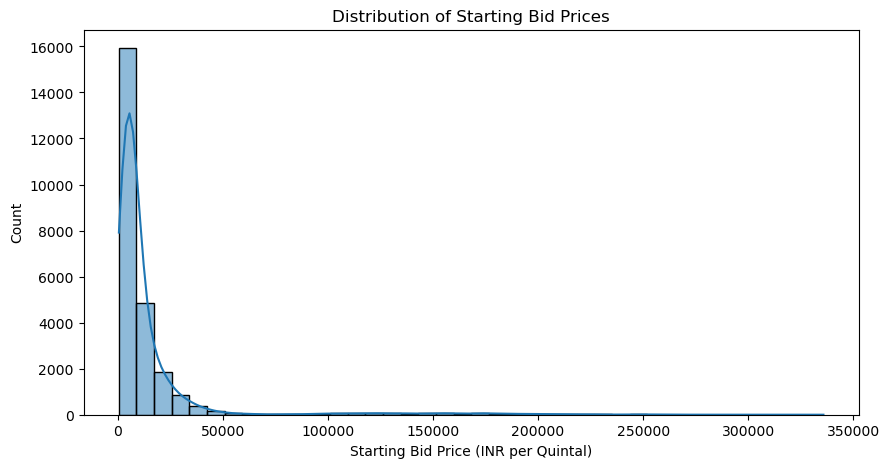

In [35]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["starting_bid_price_inr_per_quintal"],
    bins=40,
    kde=True
)

plt.title("Distribution of Starting Bid Prices")
plt.xlabel("Starting Bid Price (INR per Quintal)")

plt.show()

### 5.3 Are There Unusually High or Low Crop Prices?

A farmer selling apples and a farmer selling a different agricultural product may have very different starting prices.

Some observations may also be much higher or lower than the majority of the dataset.

These unusual observations are called potential outliers.

We will use a boxplot to visually investigate the distribution of starting bid prices.

A boxplot displays:

- Median.
- First quartile (Q1).
- Third quartile (Q3).
- Interquartile range (IQR).
- Potential outliers.

This helps us understand whether the price distribution contains extreme observations that deserve further investigation.

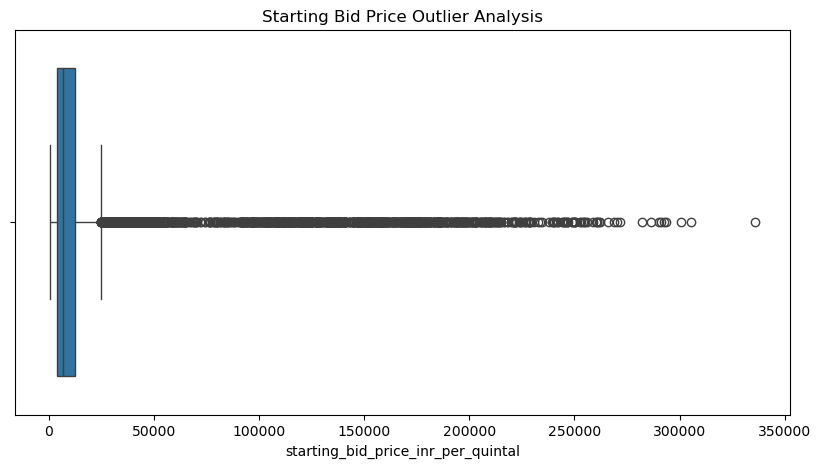

In [36]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["starting_bid_price_inr_per_quintal"]
)

plt.title("Starting Bid Price Outlier Analysis")

plt.show()

### What Have We Learned So Far?

Our univariate analysis has helped us investigate three important aspects of the agricultural market:

- Crop listing frequency.
- Distribution of starting bid prices.
- Potential price outliers.

We now have a better understanding of individual variables.

However, agricultural prices do not exist independently. They may be associated with crop type, quantity, district and season.

To investigate these relationships, we need Bivariate Analysis.

# 6. Bivariate Analysis: Discovering Relationships

Bivariate Analysis means studying two variables together.

Until now, we have examined individual columns. Now we want to understand how one variable behaves in relation to another.

Think about a farmer deciding the starting price of a crop.

He might ask:

- Does an apple listing generally have a different price from a walnut listing?
- Does a larger quantity correspond to a higher starting price?
- Are there visible patterns between crop characteristics and price?

We will investigate these questions using boxplots and scatterplots.

Our target variable throughout this analysis is:

**Starting Bid Price per Quintal.**

Bivariate Analysis


### 6.1 Does Starting Bid Price Differ Between Crops?

Different agricultural products have different market characteristics.

For example, apples, walnuts and other crops are not necessarily sold at the same price per quintal.

We will compare crop categories against starting bid prices using a boxplot.

A boxplot is useful here because it allows us to compare:

- Median price for each crop.
- Price variability within each crop.
- Potential outliers.
- Differences in price distributions.

**Question:** Which crop appears to have the highest typical starting bid price?

Remember that we should compare median prices and distributions, not simply assume that the crop with the highest individual observation is the most expensive.

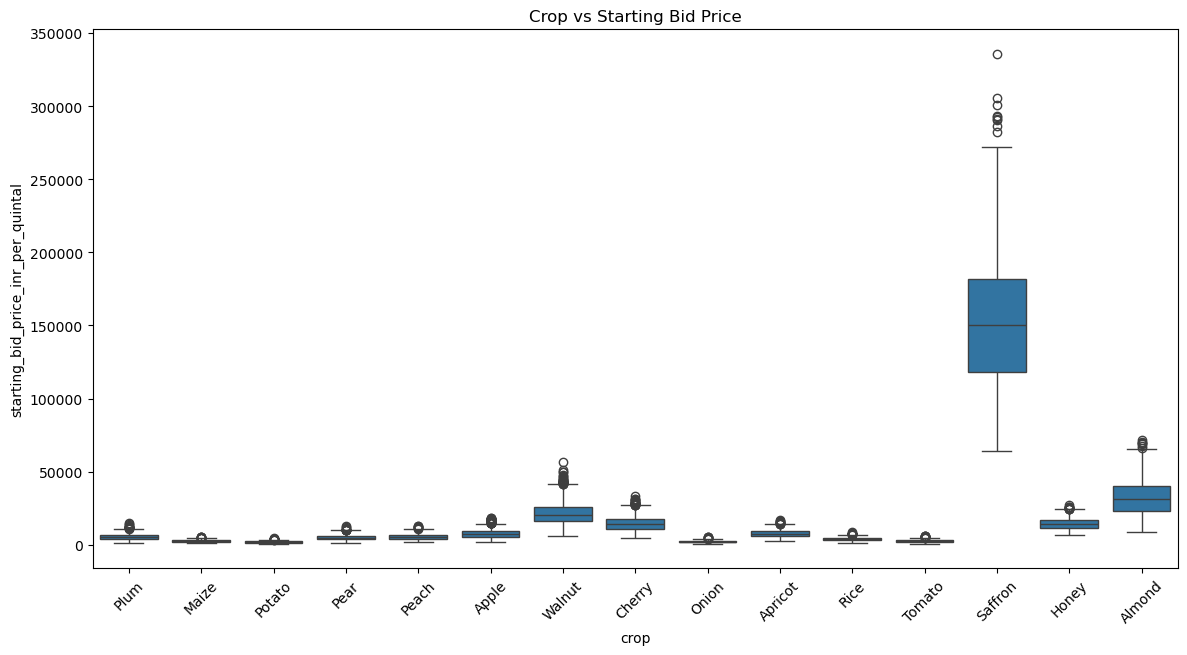

In [37]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="crop",
    y="starting_bid_price_inr_per_quintal"
)

plt.xticks(rotation=45)

plt.title("Crop vs Starting Bid Price")

plt.show()

### 6.2 Does Crop Quantity Have a Relationship With Starting Bid Price?

Imagine two farmers listing the same crop:

- Farmer A offers 20 quintals.
- Farmer B offers 200 quintals.

Does the quantity of the listing relate to its starting bid price per quintal?

To investigate this, we will use a scatterplot.

A scatterplot represents each observation as a point.

It helps us identify:

- Positive relationships.
- Negative relationships.
- Weak or unclear relationships.
- Clusters and unusual observations.

**Important statistical distinction:** A relationship between quantity and starting bid price does not prove that quantity causes a price change. Other variables, such as crop type and quality, may also influence prices.

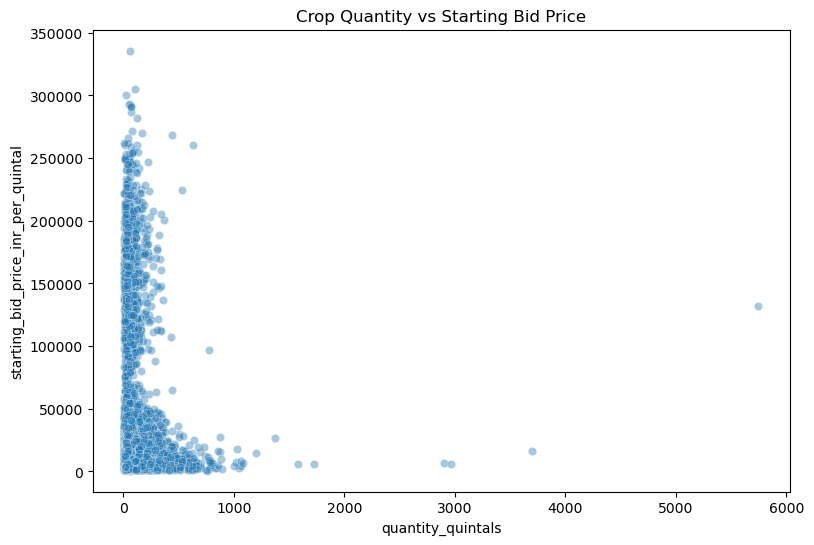

In [38]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="quantity_quintals",
    y="starting_bid_price_inr_per_quintal",
    alpha=0.4
)

plt.title("Crop Quantity vs Starting Bid Price")

plt.show()

### What Have We Discovered?

Our bivariate analysis has allowed us to compare crop categories and investigate the relationship between quantity and starting bid price.

These comparisons are useful because AgriSense needs to understand which listing characteristics may be informative for price prediction.

However, two-variable analysis gives us only part of the picture.

A crop's price may be associated with several variables simultaneously.

We therefore move to Multivariate Analysis.

# 7. Multivariate Analysis: Looking at the Bigger Picture

Agricultural markets are complex.

A crop's starting bid price may be associated with several factors:

- Quantity.
- Quality score.
- Crop type.
- Market arrival.
- Temperature.
- Rainfall.
- District and season.

Studying these variables individually may not reveal how they behave together.

Multivariate Analysis helps us investigate relationships among multiple variables.

For this investigation, we will use a correlation matrix and heatmap.

Our goal is to identify numerical relationships that may help us understand the agricultural market and select useful features for machine learning.

Multivariate Analysis

### 7.1 Understanding Correlation Between Numerical Variables

Correlation measures the strength and direction of a linear relationship between two numerical variables.

The correlation coefficient ranges from -1 to +1.

- **+1:** Perfect positive linear correlation.
- **0:** No linear correlation.
- **-1:** Perfect negative linear correlation.

We will calculate the correlation matrix using Pandas and visualize it using a Seaborn heatmap.

The heatmap makes it easier to identify numerical variables that move together.

**Why is this useful for AgriSense?**

If certain numerical variables show strong relationships with starting bid price, they may provide useful information for our machine learning model.

However, correlation does not establish causation, and a weak linear correlation does not necessarily mean a variable has no predictive value.

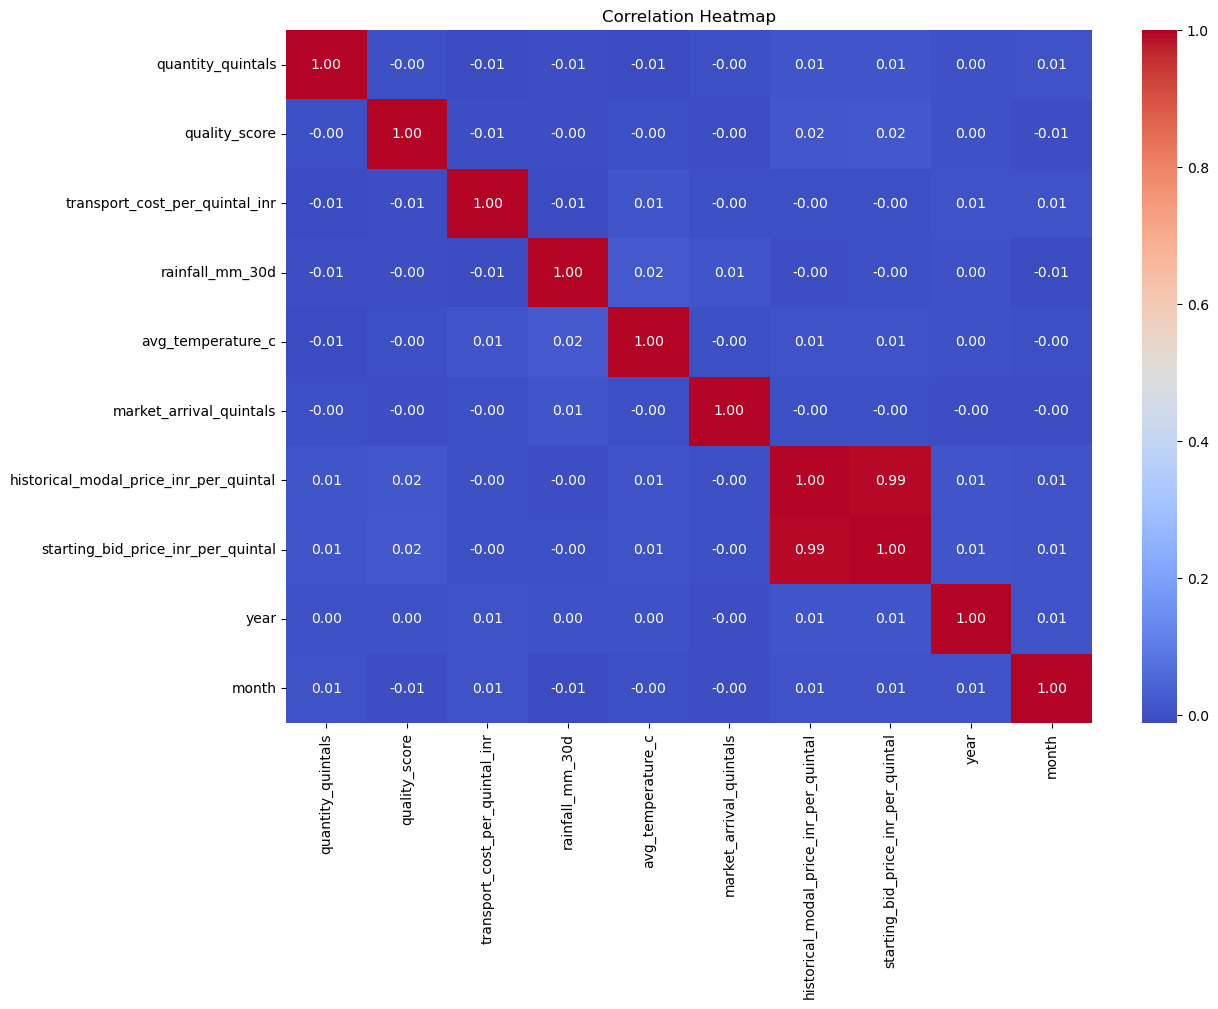

In [39]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Outlier Analysis

# 8. Outlier Analysis: Finding Unusual Agricultural Listings

During our earlier price analysis, we observed that some observations may be unusually high or low.

Now we will investigate outliers more systematically.

An outlier is an observation that lies unusually far from the majority of the data.

For example:

- A farmer listing an unusually large quantity.
- An unusually high starting bid price.
- A value that may have resulted from incorrect data entry.

Outliers are not always mistakes. A very large listing may be completely genuine.

Therefore, our goal is to detect unusual observations and investigate them, not automatically delete them.

### 8.1 Detecting Quantity Outliers Using the IQR Method

We will use the Interquartile Range (IQR) method to detect unusual crop quantities.

The IQR is calculated as:

**IQR = Q3 − Q1**

Where:

- Q1 is the 25th percentile.
- Q3 is the 75th percentile.

We calculate the lower and upper boundaries using:

**Lower Bound = Q1 − 1.5 × IQR**

**Upper Bound = Q3 + 1.5 × IQR**

Any quantity below the lower boundary or above the upper boundary is flagged as a potential outlier.

This is a statistical detection technique, not proof that an observation is incorrect.

In [40]:
Q1 = df["quantity_quintals"].quantile(0.25)

Q3 = df["quantity_quintals"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = df[
    (df["quantity_quintals"] < lower) |
    (df["quantity_quintals"] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 1609


### 8.2 Visualizing Quantity Outliers

After identifying potential outliers mathematically, we will visualize the quantity distribution using a boxplot.

This allows us to observe:

- The central distribution of crop quantities.
- The median quantity.
- The interquartile range.
- Potentially extreme observations.

The IQR calculation and boxplot complement each other.

We will retain the detected observations at this stage because genuine large agricultural listings should not be removed without a valid reason.

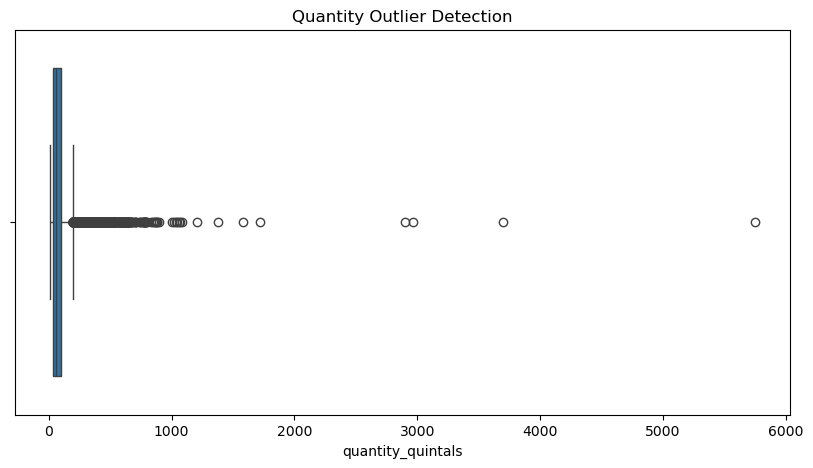

In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["quantity_quintals"])

plt.title("Quantity Outlier Detection")

plt.show()

# 9. Understanding Agricultural Markets Across Districts

Jammu & Kashmir has several agricultural regions, and market conditions may differ from one district to another.

For example, crop availability, agricultural production and market demand may vary geographically.

For AgriSense, understanding district-level price patterns is important because farmers and buyers need regional market information.

We will calculate the average starting bid price for each district.

Then we will visualize the results using a bar chart.

**Our research question:**

Which districts have the highest and lowest average starting bid prices in our dataset?

This comparison can help us understand geographical differences in the agricultural listings.

In [42]:
district_prices = df.groupby("district")[
    "starting_bid_price_inr_per_quintal"
].mean().sort_values(ascending=False)

print(district_prices)

district
Kathua       15535.403709
Doda         15462.117386
Bandipora    15287.755271
Jammu        14946.165415
Srinagar     14730.037870
Budgam       14716.921672
Shopian      14591.797701
Anantnag     14421.360571
Kupwara      14352.944641
Baramulla    14268.408990
Kulgam       14237.361166
Rajouri      13986.213435
Udhampur     13934.949910
Pulwama      13639.496473
Ganderbal    13324.518745
Name: starting_bid_price_inr_per_quintal, dtype: float64


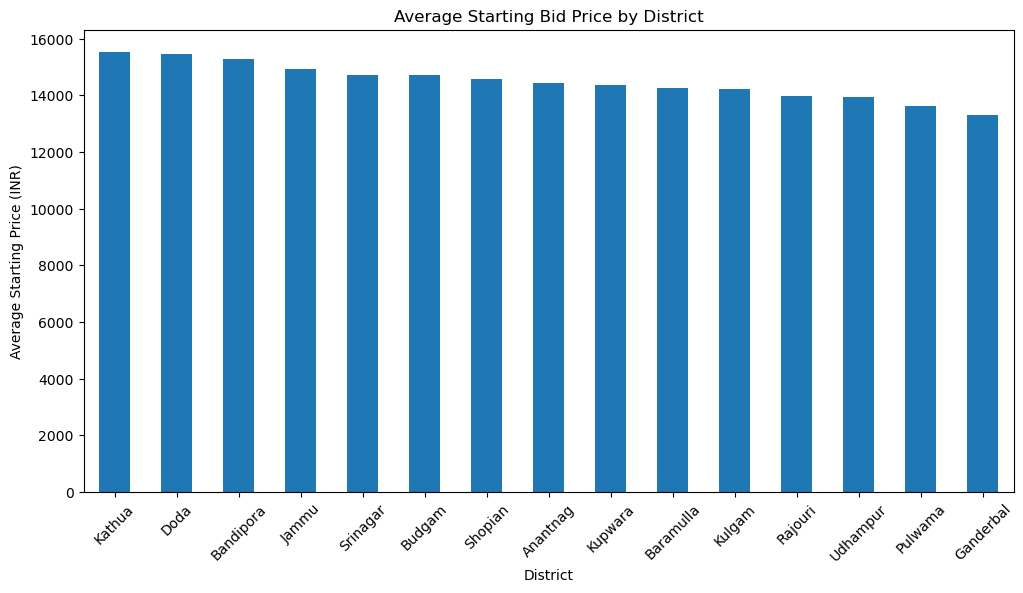

In [43]:
plt.figure(figsize=(12, 6))

district_prices.plot(kind="bar")

plt.title("Average Starting Bid Price by District")

plt.xlabel("District")

plt.ylabel("Average Starting Price (INR)")

plt.xticks(rotation=45)

plt.show()

# 10. Does Season Matter in Agricultural Pricing?

Agriculture is closely connected to seasons.

Different crops are harvested during different periods, and agricultural market conditions may change throughout the year.

For example, the availability of a particular crop may increase during its harvesting season.

This could be associated with changes in starting bid prices.

We will group our observations by season and calculate the average starting bid price.

A bar chart will help us compare the average prices across seasons.

**Our research question:**

Do we observe differences in average starting bid prices between seasons?

This analysis may help AgriSense identify seasonal patterns that could be useful when estimating starting prices.

Remember that average differences alone do not establish that season causes price changes.

In [45]:
season_prices = df.groupby("season")[
    "starting_bid_price_inr_per_quintal"
].mean()

print(season_prices)

season
Autumn    15268.370202
Spring    14934.209772
Summer    13839.816553
Winter    13628.753929
Name: starting_bid_price_inr_per_quintal, dtype: float64


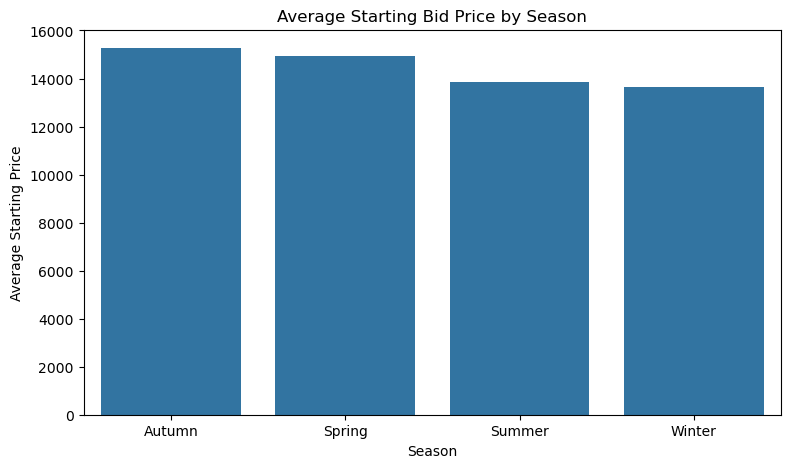

In [46]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=season_prices.index,
    y=season_prices.values
)

plt.title("Average Starting Bid Price by Season")

plt.xlabel("Season")

plt.ylabel("Average Starting Price")

plt.show()

# 11. What Did Our Investigation Reveal?

We have now completed the major stages of Exploratory Data Analysis.

Let's summarize what we investigated.

### Data Cleaning
- Identified missing values and handled them using median and mode imputation.
- Removed the selected column with approximately 35% missing values.
- Removed duplicate records.
- Standardized categorical values.
- Extracted year and month from listing dates.

### Univariate Analysis
- Identified the most frequently listed crops.
- Investigated the distribution of starting bid prices.
- Examined potential price outliers.

### Bivariate Analysis
- Compared starting bid prices across crop categories.
- Investigated the relationship between crop quantity and starting bid price.

### Multivariate Analysis
- Examined correlations between numerical variables using a heatmap.

### Outlier Analysis
- Applied the IQR method to detect unusual crop quantities.
- Visualized quantity distributions using a boxplot.

### Market Analysis
- Compared average starting bid prices across districts.
- Investigated seasonal differences in average starting bid prices.

### Why does this matter?

We now have a better understanding of the structure, quality and statistical patterns in our agricultural dataset.

These findings provide the foundation for the next stage of AgriSense: Machine Learning.

Our next objective is to train regression models that can estimate a suggested starting bid price from historical listing information.

# 12. Preparing the Dataset for Machine Learning

Our EDA investigation is complete.

However, the work does not end with visualizations.

We need to preserve the cleaned dataset so that it can be used in our machine learning notebook.

We will export the cleaned data into a new CSV file.

This file will contain the processed records after our cleaning and standardization operations.

In the next stage, we will:

1. Select input features and the target variable.
2. Separate numerical and categorical features.
3. Apply preprocessing and encoding.
4. Split the data into training and testing sets.
5. Train and compare regression models.
6. Evaluate their performance using MAE, RMSE and R².

**Our EDA notebook has prepared the data. Now the machine learning notebook will use it to learn price patterns.**

In [48]:
df.to_csv(
    "KisanBid_Cleaned_Dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [49]:
import sklearn

print("Jupyter scikit-learn version:",
      sklearn.__version__)

Jupyter scikit-learn version: 1.4.2
